In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [23]:
# mu_q = 0
# var_q = 0.5

mu_q = 3
var_q = 0.5

sd_q = np.sqrt(var_q)

alpha = 11
lam = 13

var_e = 0.001
sq_e = np.sqrt(var_e)

In [24]:
def f(theta):
	if theta <= 0:
		return 0
	return np.exp(-13*theta) * theta**10

def q(theta):
	return norm.pdf(theta, loc=mu_q, scale=sd_q)

In [25]:
n = 100000

theta = np.zeros(n + 1)
theta[0] = 1.0
burn_in = 1000
accepted = 0

for t in range(n):
	e = np.random.normal(0, sq_e)
	a = theta[t] + e
	r = f(a) / f(theta[t])

	if np.random.rand() < min(1, r):
		theta[t + 1] = a
		accepted += 1
	else:
		theta[t + 1] = theta[t]
samples = theta[burn_in + 1:]
print(f"------------------ n = {n}------------------")
print(f"受容率: {accepted / n}")
print(f"MCMC平均: {np.mean(samples)}")
print(f"MCMC分散: {np.var(samples)}")

print(f"理論値平均: {alpha / lam}")
print(f"理論値分散: {alpha / lam**2}")
		

------------------ n = 100000------------------
受容率: 0.96065
MCMC平均: 0.8535547263021029
MCMC分散: 0.059171788272470174
理論値平均: 0.8461538461538461
理論値分散: 0.0650887573964497


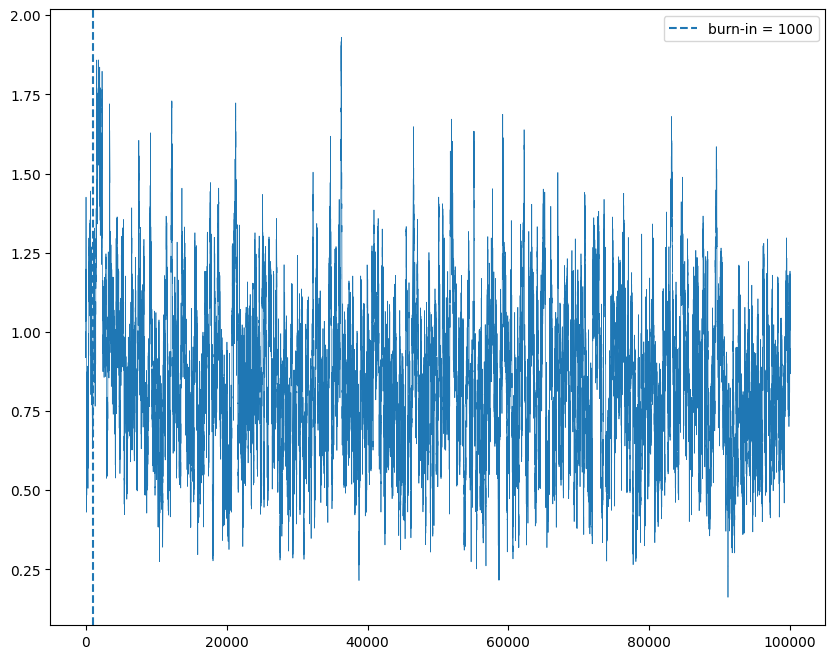

In [26]:
plt.figure(figsize=(10, 8))
plt.plot(theta, linewidth=0.5)
plt.axvline(x=burn_in, linestyle="--", label=f"burn-in = {burn_in}")
plt.legend()
plt.show()